In [1]:

from google.colab import files
uploaded = files.upload()


Saving wine+quality.zip to wine+quality.zip


In [2]:

import zipfile
import os

zip_file = "wine+quality.zip"
extract_folder = "/content/wine_data"

with zipfile.ZipFile(zip_file, "r") as zip_ref:
    zip_ref.extractall(extract_folder)

print("Files extracted successfully!")
print(os.listdir(extract_folder))


Files extracted successfully!
['winequality-white.csv', 'winequality-red.csv', 'winequality.names']


In [3]:

import pandas as pd

# Load red and white wine datasets
red_wine = pd.read_csv(
    "/content/wine_data/winequality-red.csv",
    sep=";"
)

white_wine = pd.read_csv(
    "/content/wine_data/winequality-white.csv",
    sep=";"
)

# Display dataset dimensions
print("RED WINE DATASET")
print("Shape:", red_wine.shape)
print("\nWHITE WINE DATASET")
print("Shape:", white_wine.shape)

# Display column names
print("\nColumn names:")
print(red_wine.columns.tolist())

# Display first five rows
print("\nFirst 5 rows of red wine:")
display(red_wine.head())

print("\nFirst 5 rows of white wine:")
display(white_wine.head())


RED WINE DATASET
Shape: (1599, 12)

WHITE WINE DATASET
Shape: (4898, 12)

Column names:
['fixed acidity', 'volatile acidity', 'citric acid', 'residual sugar', 'chlorides', 'free sulfur dioxide', 'total sulfur dioxide', 'density', 'pH', 'sulphates', 'alcohol', 'quality']

First 5 rows of red wine:


,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality
0,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5
1,7.8,0.88,0.00,2.6,0.098,25.0,67.0,0.9968,3.20,0.68,9.8,5
2,7.8,0.76,0.04,2.3,0.092,15.0,54.0,0.9970,3.26,0.65,9.8,5
3,11.2,0.28,0.56,1.9,0.075,17.0,60.0,0.9980,3.16,0.58,9.8,6
4,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5



First 5 rows of white wine:


,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality
0,7.0,0.27,0.36,20.7,0.045,45.0,170.0,1.0010,3.00,0.45,8.8,6
1,6.3,0.30,0.34,1.6,0.049,14.0,132.0,0.9940,3.30,0.49,9.5,6
2,8.1,0.28,0.40,6.9,0.050,30.0,97.0,0.9951,3.26,0.44,10.1,6
3,7.2,0.23,0.32,8.5,0.058,47.0,186.0,0.9956,3.19,0.40,9.9,6
4,7.2,0.23,0.32,8.5,0.058,47.0,186.0,0.9956,3.19,0.40,9.9,6


In [4]:

print("RED WINE DATA QUALITY")
print("Missing values:", red_wine.isnull().sum().sum())
print("Duplicate rows:", red_wine.duplicated().sum())

print("\nWHITE WINE DATA QUALITY")
print("Missing values:", white_wine.isnull().sum().sum())
print("Duplicate rows:", white_wine.duplicated().sum())


RED WINE DATA QUALITY
Missing values: 0
Duplicate rows: 240

WHITE WINE DATA QUALITY
Missing values: 0
Duplicate rows: 937


In [5]:

# Attributes required for statistical analysis
attributes = ["alcohol", "volatile acidity", "residual sugar"]

def statistical_analysis(data, wine_type):
    print(f"\n{'='*20} {wine_type} WINE {'='*20}")

    for column in attributes:
        print(f"\nAttribute: {column}")
        print("Mean:", round(data[column].mean(), 3))
        print("Median:", round(data[column].median(), 3))
        print("Mode:", data[column].mode().tolist())
        print("Standard Deviation:", round(data[column].std(), 3))
        print("Skewness:", round(data[column].skew(), 3))

# Analyze red wine
statistical_analysis(red_wine, "RED")

# Analyze white wine
statistical_analysis(white_wine, "WHITE")



==================== RED WINE ====================

Attribute: alcohol
Mean: 10.423
Median: 10.2
Mode: [9.5]
Standard Deviation: 1.066
Skewness: 0.861

Attribute: volatile acidity
Mean: 0.528
Median: 0.52
Mode: [0.6]
Standard Deviation: 0.179
Skewness: 0.672

Attribute: residual sugar
Mean: 2.539
Median: 2.2
Mode: [2.0]
Standard Deviation: 1.41
Skewness: 4.541

==================== WHITE WINE ====================

Attribute: alcohol
Mean: 10.514
Median: 10.4
Mode: [9.4]
Standard Deviation: 1.231
Skewness: 0.487

Attribute: volatile acidity
Mean: 0.278
Median: 0.26
Mode: [0.28]
Standard Deviation: 0.101
Skewness: 1.577

Attribute: residual sugar
Mean: 6.391
Median: 5.2
Mode: [1.2]
Standard Deviation: 5.072
Skewness: 1.077


In [6]:

import pandas as pd

attributes = ["alcohol", "volatile acidity", "residual sugar"]

# Calculate coefficient of variation (CV)
for name, data in [("Red Wine", red_wine), ("White Wine", white_wine)]:
    print(f"\n{name} - Coefficient of Variation")
    for column in attributes:
        cv = (data[column].std() / data[column].mean()) * 100
        print(f"{column}: {cv:.2f}%")

# Pearson correlation between alcohol and quality
red_corr = red_wine["alcohol"].corr(red_wine["quality"])
white_corr = white_wine["alcohol"].corr(white_wine["quality"])

print("\nAlcohol vs Quality Correlation")
print(f"Red wine: {red_corr:.3f}")
print(f"White wine: {white_corr:.3f}")



Red Wine - Coefficient of Variation
alcohol: 10.22%
volatile acidity: 33.92%
residual sugar: 55.54%

White Wine - Coefficient of Variation
alcohol: 11.70%
volatile acidity: 36.23%
residual sugar: 79.36%

Alcohol vs Quality Correlation
Red wine: 0.476
White wine: 0.436


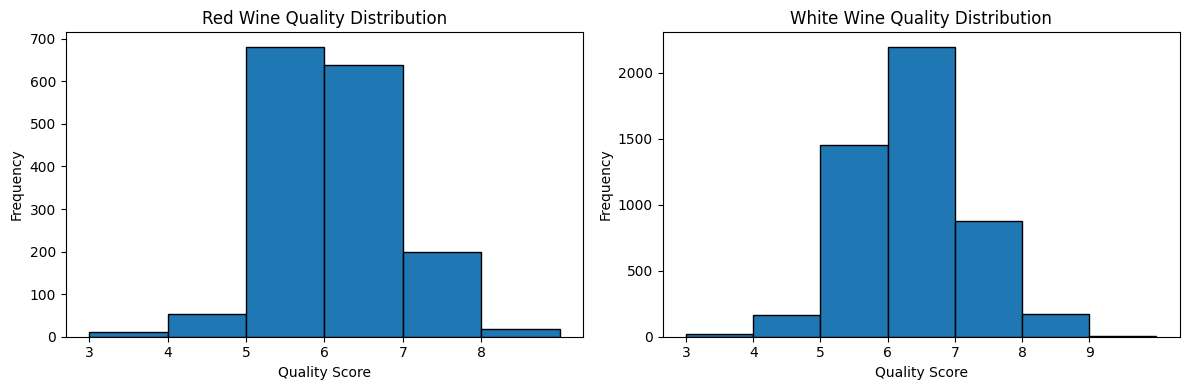

In [7]:

import matplotlib.pyplot as plt

# Quality score distribution for red and white wines
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].hist(red_wine["quality"], bins=range(3, 10), edgecolor="black")
axes[0].set_title("Red Wine Quality Distribution")
axes[0].set_xlabel("Quality Score")
axes[0].set_ylabel("Frequency")
axes[0].set_xticks(sorted(red_wine["quality"].unique()))

axes[1].hist(white_wine["quality"], bins=range(3, 11), edgecolor="black")
axes[1].set_title("White Wine Quality Distribution")
axes[1].set_xlabel("Quality Score")
axes[1].set_ylabel("Frequency")
axes[1].set_xticks(sorted(white_wine["quality"].unique()))

plt.tight_layout()
plt.show()


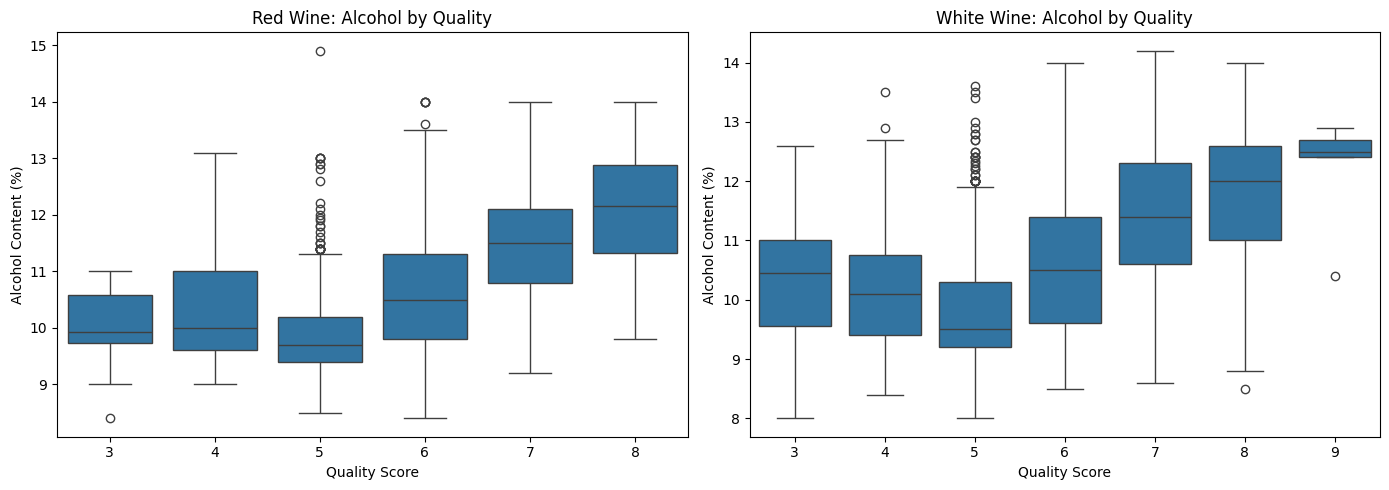

In [8]:

import matplotlib.pyplot as plt
import seaborn as sns

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Red wine box plot
sns.boxplot(data=red_wine, x="quality", y="alcohol", ax=axes[0])
axes[0].set_title("Red Wine: Alcohol by Quality")
axes[0].set_xlabel("Quality Score")
axes[0].set_ylabel("Alcohol Content (%)")

# White wine box plot
sns.boxplot(data=white_wine, x="quality", y="alcohol", ax=axes[1])
axes[1].set_title("White Wine: Alcohol by Quality")
axes[1].set_xlabel("Quality Score")
axes[1].set_ylabel("Alcohol Content (%)")

plt.tight_layout()
plt.show()


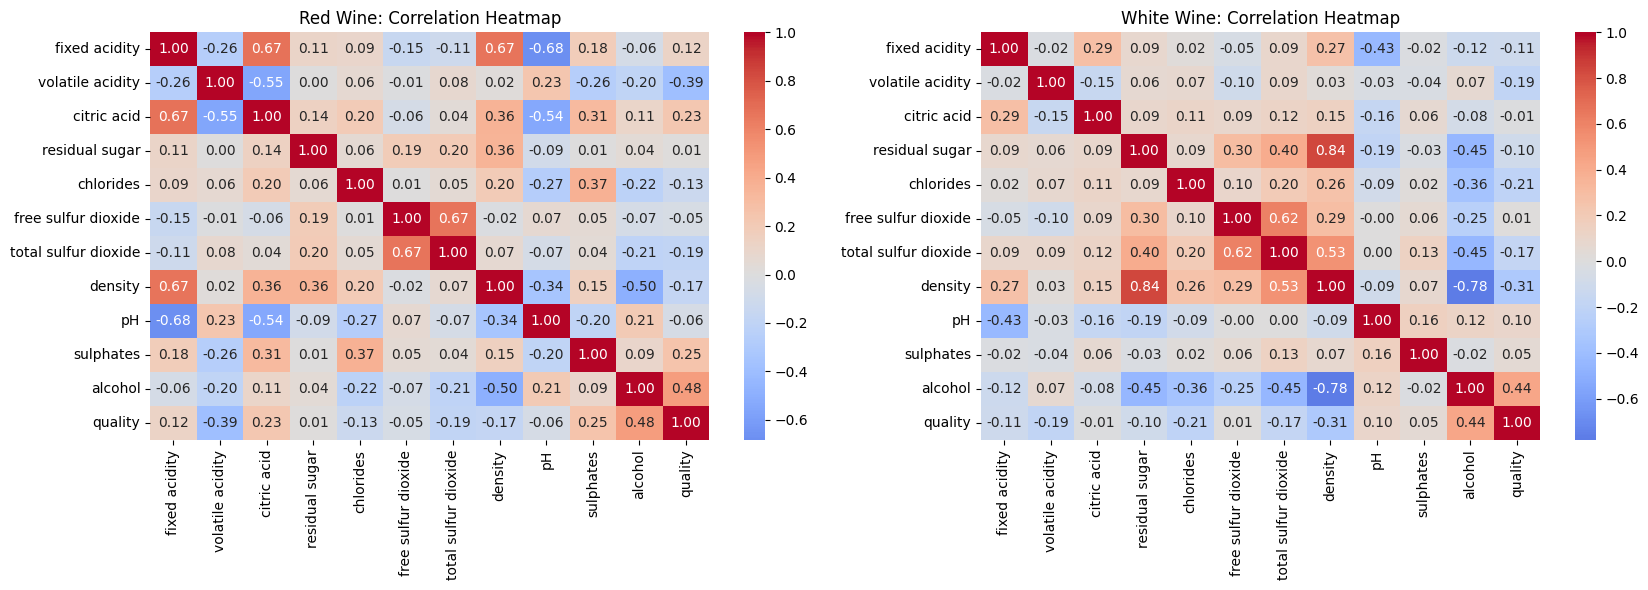

In [9]:

import matplotlib.pyplot as plt
import seaborn as sns

fig, axes = plt.subplots(1, 2, figsize=(17, 6))

sns.heatmap(
    red_wine.corr(), annot=True, fmt=".2f",
    cmap="coolwarm", center=0, ax=axes[0]
)
axes[0].set_title("Red Wine: Correlation Heatmap")

sns.heatmap(
    white_wine.corr(), annot=True, fmt=".2f",
    cmap="coolwarm", center=0, ax=axes[1]
)
axes[1].set_title("White Wine: Correlation Heatmap")

plt.tight_layout()
plt.show()


In [10]:

for name, data in [("Red Wine", red_wine), ("White Wine", white_wine)]:
    correlations = data.corr(numeric_only=True)["quality"].drop("quality")
    strongest = correlations.reindex(
        correlations.abs().sort_values(ascending=False).index
    ).head(2)

    print(f"\n{name} - Two strongest correlations with quality:")
    print(strongest.round(3))



Red Wine - Two strongest correlations with quality:
alcohol             0.476
volatile acidity   -0.391
Name: quality, dtype: float64

White Wine - Two strongest correlations with quality:
alcohol    0.436
density   -0.307
Name: quality, dtype: float64


In [11]:

import numpy as np
import pandas as pd

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

def build_regression_model(data, wine_type):
    # Separate predictors and target
    X = data.drop(columns=["quality"])
    y = data["quality"]

    # Split into training and testing data
    X_train, X_test, y_train, y_test = train_test_split(
        X, y, test_size=0.20, random_state=42
    )

    # Train the regression model
    model = LinearRegression()
    model.fit(X_train, y_train)

    # Predict quality scores
    y_pred = model.predict(X_test)

    # Evaluate model performance
    mae = mean_absolute_error(y_test, y_pred)
    mse = mean_squared_error(y_test, y_pred)
    rmse = np.sqrt(mse)
    r2 = r2_score(y_test, y_pred)

    print(f"\n{'='*15} {wine_type} WINE MODEL {'='*15}")
    print("Training rows:", len(X_train))
    print("Testing rows:", len(X_test))
    print(f"MAE:  {mae:.4f}")
    print(f"MSE:  {mse:.4f}")
    print(f"RMSE: {rmse:.4f}")
    print(f"R²:   {r2:.4f}")

    # Calculate standardized regression coefficients
    scaler_X = StandardScaler()
    scaler_y = StandardScaler()

    X_train_scaled = scaler_X.fit_transform(X_train)
    y_train_scaled = scaler_y.fit_transform(
        y_train.to_numpy().reshape(-1, 1)
    ).ravel()

    standardized_model = LinearRegression()
    standardized_model.fit(X_train_scaled, y_train_scaled)

    coefficients = pd.Series(
        standardized_model.coef_,
        index=X.columns
    ).sort_values(key=abs, ascending=False)

    print("\nStandardized coefficients (largest absolute values first):")
    print(coefficients.round(4))

    return model, X_test, y_test, y_pred, coefficients

# Build separate models
red_model, red_X_test, red_y_test, red_pred, red_coef = (
    build_regression_model(red_wine, "RED")
)

white_model, white_X_test, white_y_test, white_pred, white_coef = (
    build_regression_model(white_wine, "WHITE")
)



=============== RED WINE MODEL ===============
Training rows: 1279
Testing rows: 320
MAE:  0.5035
MSE:  0.3900
RMSE: 0.6245
R²:   0.4032

Standardized coefficients (largest absolute values first):
alcohol                 0.3678
volatile acidity       -0.2225
sulphates               0.1820
total sulfur dioxide   -0.1488
chlorides              -0.1104
pH                     -0.0751
free sulfur dioxide     0.0719
fixed acidity           0.0493
citric acid            -0.0341
density                -0.0238
residual sugar          0.0117
dtype: float64

=============== WHITE WINE MODEL ===============
Training rows: 3918
Testing rows: 980
MAE:  0.5863
MSE:  0.5690
RMSE: 0.7543
R²:   0.2653

Standardized coefficients (largest absolute values first):
density                -0.4234
residual sugar          0.4128
alcohol                 0.3171
volatile acidity       -0.2194
pH                      0.1017
free sulfur dioxide     0.0963
sulphates               0.0831
fixed acidity           0.043

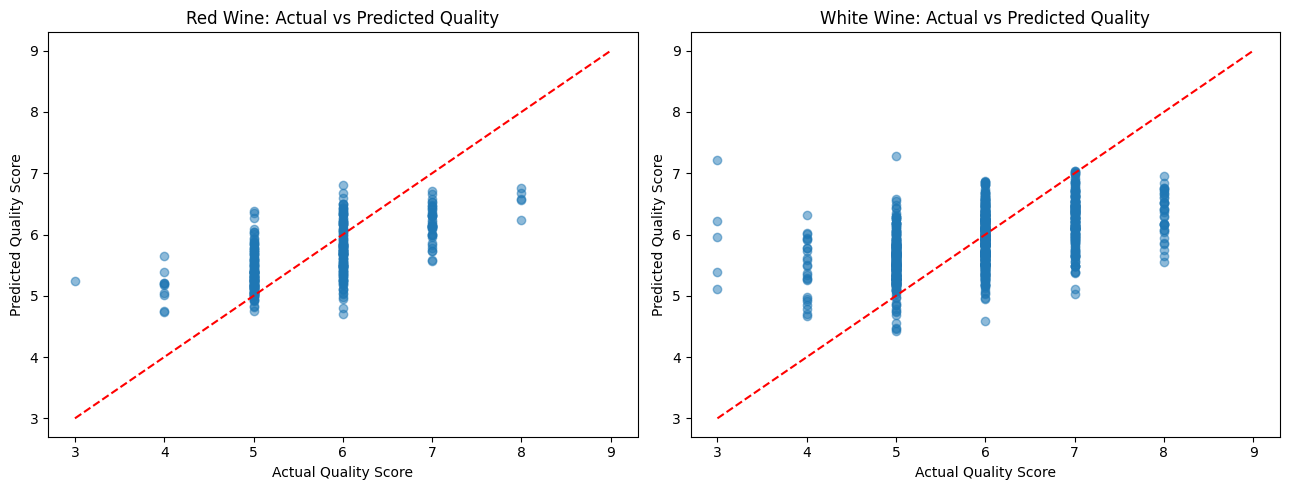

In [12]:

import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

# Red wine: actual vs predicted
axes[0].scatter(red_y_test, red_pred, alpha=0.5)
axes[0].plot([3, 9], [3, 9], "r--")
axes[0].set_title("Red Wine: Actual vs Predicted Quality")
axes[0].set_xlabel("Actual Quality Score")
axes[0].set_ylabel("Predicted Quality Score")

# White wine: actual vs predicted
axes[1].scatter(white_y_test, white_pred, alpha=0.5)
axes[1].plot([3, 9], [3, 9], "r--")
axes[1].set_title("White Wine: Actual vs Predicted Quality")
axes[1].set_xlabel("Actual Quality Score")
axes[1].set_ylabel("Predicted Quality Score")

plt.tight_layout()
plt.show()


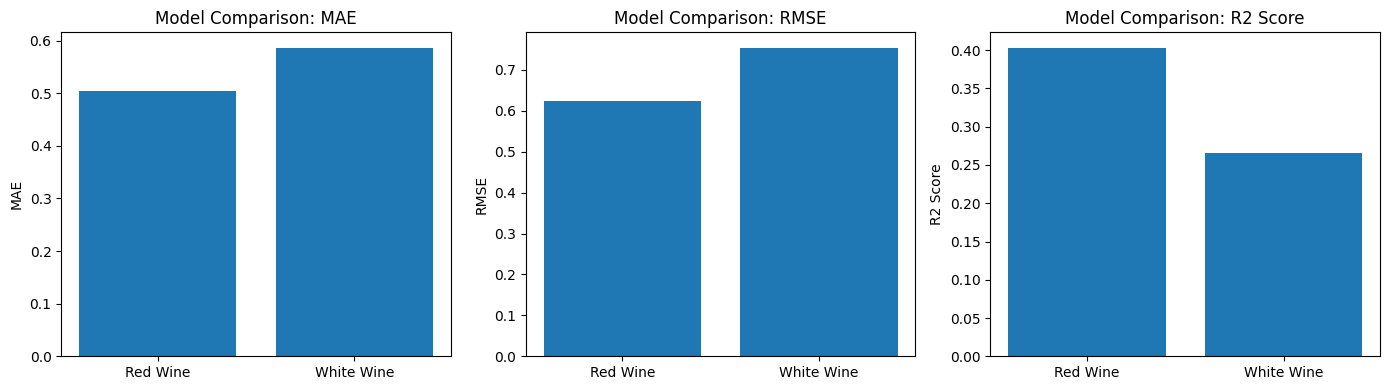

,Wine Type,MAE,RMSE,R2 Score
0,Red Wine,0.5035,0.6245,0.4032
1,White Wine,0.5863,0.7543,0.2653


In [14]:

import pandas as pd
import matplotlib.pyplot as plt

comparison = pd.DataFrame({
    "Wine Type": ["Red Wine", "White Wine"],
    "MAE": [0.5035, 0.5863],
    "RMSE": [0.6245, 0.7543],
    "R2 Score": [0.4032, 0.2653]
})

fig, axes = plt.subplots(1, 3, figsize=(14, 4))

for ax, metric in zip(axes, ["MAE", "RMSE", "R2 Score"]):
    ax.bar(comparison["Wine Type"], comparison[metric])
    ax.set_title(f"Model Comparison: {metric}")
    ax.set_ylabel(metric)

plt.tight_layout()
plt.show()

display(comparison)


In [15]:

summary = pd.DataFrame({
    "Metric": ["MAE", "MSE", "RMSE", "R2 Score"],
    "Red Wine": [
        mean_absolute_error(red_y_test, red_pred),
        mean_squared_error(red_y_test, red_pred),
        mean_squared_error(red_y_test, red_pred) ** 0.5,
        r2_score(red_y_test, red_pred)
    ],
    "White Wine": [
        mean_absolute_error(white_y_test, white_pred),
        mean_squared_error(white_y_test, white_pred),
        mean_squared_error(white_y_test, white_pred) ** 0.5,
        r2_score(white_y_test, white_pred)
    ]
})

print("FINAL REGRESSION RESULTS")
display(summary.round(4))

print("\nTop 2 predictors for Red Wine:")
display(red_coef.head(2))

print("\nTop 2 predictors for White Wine:")
display(white_coef.head(2))


FINAL REGRESSION RESULTS


,Metric,Red Wine,White Wine
0,MAE,0.5035,0.5863
1,MSE,0.3900,0.5690
2,RMSE,0.6245,0.7543
3,R2 Score,0.4032,0.2653



Top 2 predictors for Red Wine:


,0
alcohol,0.367754
volatile acidity,-0.222465



Top 2 predictors for White Wine:


,0
density,-0.423365
residual sugar,0.412805


In [16]:

import numpy as np
import pandas as pd

def find_high_correlations(data, wine_type, threshold=0.70):
    corr_matrix = data.drop(columns=["quality"]).corr().abs()

    # Keep only the upper triangle to avoid duplicate pairs
    upper_triangle = corr_matrix.where(
        np.triu(np.ones(corr_matrix.shape), k=1).astype(bool)
    )

    pairs = (
        upper_triangle.stack()
        .reset_index()
    )
    pairs.columns = ["Attribute 1", "Attribute 2", "Absolute Correlation"]

    pairs = pairs[pairs["Absolute Correlation"] >= threshold]
    pairs = pairs.sort_values("Absolute Correlation", ascending=False)

    print(f"\n{wine_type} Wine - Highly Correlated Predictor Pairs")
    if pairs.empty:
        print("No predictor pairs met the threshold.")
    else:
        display(pairs.round(3))

find_high_correlations(red_wine, "Red")
find_high_correlations(white_wine, "White")



Red Wine - Highly Correlated Predictor Pairs
No predictor pairs met the threshold.

White Wine - Highly Correlated Predictor Pairs


,Attribute 1,Attribute 2,Absolute Correlation
30,residual sugar,density,0.839
51,density,alcohol,0.780


### Interpretation of Results

The statistical analysis of red and white wine datasets revealed differences in their physicochemical properties. Red wine showed a higher average volatile acidity, while white wine had a higher average residual sugar content. The coefficient of variation analysis indicated that residual sugar had the greatest relative variability in both datasets, particularly in white wine.

Pearson correlation analysis showed a moderate positive relationship between alcohol content and quality for red wine (r = 0.476) and white wine (r = 0.436). The correlation heatmaps further indicated that volatile acidity was negatively associated with red wine quality, while density was negatively associated with white wine quality.

The box plots suggested that higher-quality wines generally tended to have higher alcohol content, although the distributions overlapped. Multiple linear regression was used to predict quality scores using the 11 physicochemical attributes. The red wine model achieved an MAE of 0.5035, RMSE of 0.6245, and R² of 0.4032. The white wine model achieved an MAE of 0.5863, RMSE of 0.7543, and R² of 0.2653.

The red wine model performed better on the test set according to all reported evaluation metrics. The standardized coefficients identified alcohol and volatile acidity as the leading predictors for red wine, while density and residual sugar were the leading predictors for white wine. Strong correlations among some white wine predictors indicate potential multicollinearity, which may affect the stability of individual regression coefficients.

### Business Recommendations

1. **Red wine screening:** Prioritize alcohol content and volatile acidity as preliminary screening measurements.
2. **White wine screening:** Prioritize alcohol content and density as preliminary screening measurements.
3. **Use of regression:** Use the regression models as decision-support tools for preliminary screening rather than as replacements for sensory evaluation.
4. **Further improvement:** Evaluate additional predictive methods and validate the models on independent data before using them in practical quality-control decisions.

These recommendations should be treated as preliminary because the models explain only part of the variation in wine quality.

### Limitations of the Study

1. **Limited predictive performance:** The models explain approximately 40.32% of test-set quality variation for red wine and 26.53% for white wine.
2. **Subjective quality scores:** Wine quality scores are based on sensory assessments and may involve human judgment.
3. **Multicollinearity:** Strong correlations between some white wine predictors, particularly residual sugar and density, may affect coefficient stability.
4. **Duplicate records:** The original datasets contain duplicate rows. Their treatment should be documented because duplicates can affect statistical analysis and model evaluation.
5. **Model limitations:** Multiple linear regression assumes a linear relationship between predictors and the target, which may not fully represent the complex factors influencing wine quality.

### Conclusion

This case study investigated the relationship between physicochemical properties and wine quality using red and white wine datasets. Statistical analysis and exploratory data analysis identified important differences in alcohol content, volatile acidity, residual sugar, and other attributes.

Multiple linear regression models were developed using an 80:20 train-test split. The red wine model achieved better test-set performance than the white wine model, with an R² of 0.4032 compared with 0.2653. Alcohol was an important predictor for both wine types, while volatile acidity was influential for red wine and density and residual sugar were influential for white wine.

The findings suggest that physicochemical measurements can support preliminary wine quality screening. However, the predictive performance of the models is not sufficient to justify replacing sensory evaluation entirely. Future work could investigate additional predictive models, address multicollinearity, and evaluate performance using independent datasets.

Overall, the study demonstrates how statistical analysis, visualization, and machine learning can be used to investigate wine quality and support data-driven decisions.